# Results

In [1]:
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    RocCurveDisplay,
    accuracy_score,
    auc,
    confusion_matrix,
    roc_curve,
)
from sklearn.model_selection import GroupKFold
from sklearn.svm import SVC
from toolbox import Masking
from toolbox.evaluation import load_top_Fsel_Msel
from toolbox.processing import augment_patient_and_cat_specific
from toolbox.results import Results_data_loading, ResultsROCAUC

warnings.filterwarnings("ignore")
IIVV = np.loadtxt("source/IIVV_patterns.txt", dtype=int)
mask = Masking(IIVV)
mask.prints = False

In [3]:
# define number of group splits
cv = GroupKFold(n_splits=5)
parameter_type = "tuned"  # "default"
results_path = "results_cm"

## Task 1 : healthy versus cancer


	Info:	np.abs(Zdata)

Remaining data samples: 276 
	Info:	Select only data Avg_Cutpats <60%

Remaining data samples: 260 

	Info:	z-score Zdata
before: 443.1566344679978 707.062822308054
Normalized along the frequency axis.

after: -6.353090079251737e-18 0.9999999999999997

	Info:	np.nan_to_num(Zdata)

Remaining data samples: 260 
Healthy vs. cancer

Healthy: 90 entries
Cancer: 96 entries
Available cases: ['Cancer' 'Healthy']
Coding: -> forward
{'Cancer': [1, 0], 'Healthy': [0, 1]}


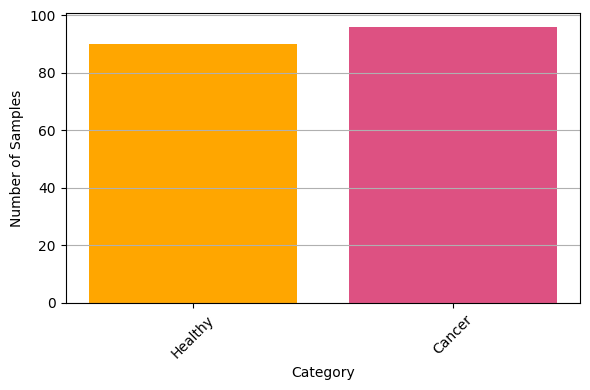


Inverse mapping: {(1, 0): 'Cancer', (0, 1): 'Healthy'}
(186, 31, 7728) (186, 2) (186,)
3.9588167667388916


In [4]:
class_task = "healthy_vs_cancer"

n_folds = 5  # number of iterations inside each LPOCV
output_prints = False
start = time.time()
Freq_sel, Mask_sel = load_top_Fsel_Msel(class_task)
X, Y_labels, labels, Case, inverse_mapping, Y = Results_data_loading(class_task)
end = time.time()
print(end - start)  # time in seconds

**SVM**

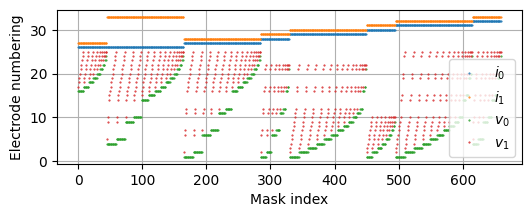

(186, 3300)


In [5]:
Msel = "Adj. far"
Fsel = "Top 5"
if parameter_type == "default":
    m = SVC(probability=True, random_state=0)
elif parameter_type == "tuned":
    m = SVC(kernel="rbf", C=10.0, probability=True)

mask.IIVV_mask(Mask_sel[Msel], plot=True)
# select freq and IIVV and shape data
X_tmp = X[:, Freq_sel[Fsel], :]
X_tmp = X_tmp[:, :, mask.mask]
X_tmp = X_tmp.reshape(X_tmp.shape[0], -1)
print(X_tmp.shape)

In [6]:
y_true = []
y_score = []
y_pred = []

predict_durations = []
pred_test_samples = 0

# Cross-validation loop
for train_idx, test_idx in cv.split(X_tmp, Y_labels, Case):
    X_train, X_test = X_tmp[train_idx], X_tmp[test_idx]
    y_train, y_test = Y_labels[train_idx], Y_labels[test_idx]
    m.fit(X_train, y_train)

    t0 = time.time()
    probs = m.predict_proba(X_test)
    preds = np.argmax(probs, axis=1)
    t1 = time.time()

    pred_test_samples += len(test_idx)
    predict_durations.append((t1 - t0))

    y_true.extend(y_test)
    y_score.extend(probs)
    y_pred.extend(preds)

y_true = np.array(y_true)
y_score = np.array(y_score)
y_pred = np.array(y_pred)

acc = accuracy_score(y_true, y_pred)
print("CV Accuracy:", acc)

CV Accuracy: 0.7956989247311828


In [7]:
np.savez(
    f"{results_path}/timings_{parameter_type}_{class_task}_SVM.npz",
    model_type="Tuned",
    model="SVM",
    class_task=class_task,
    timings_CV_iter=predict_durations,
)

AUC = 0.850462962962963


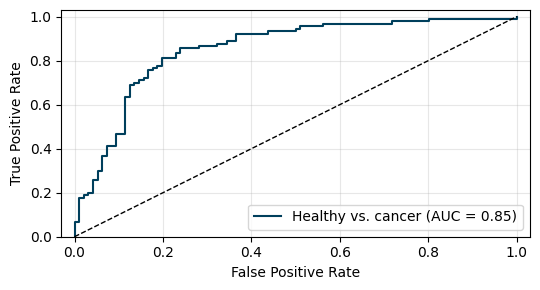

In [8]:
ResultsROCAUC(
    class_task,
    y_true,
    y_score,
    Y_labels,
    s_name=f"{results_path}/ROC_{parameter_type}_{class_task}_SVM.pdf",
)

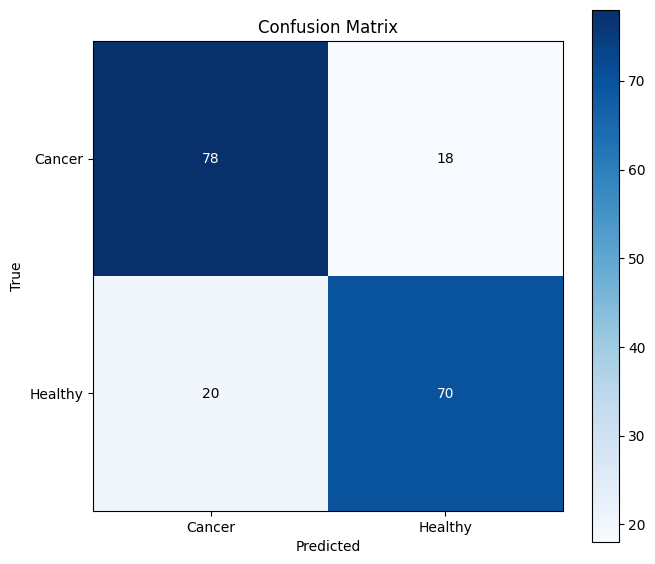

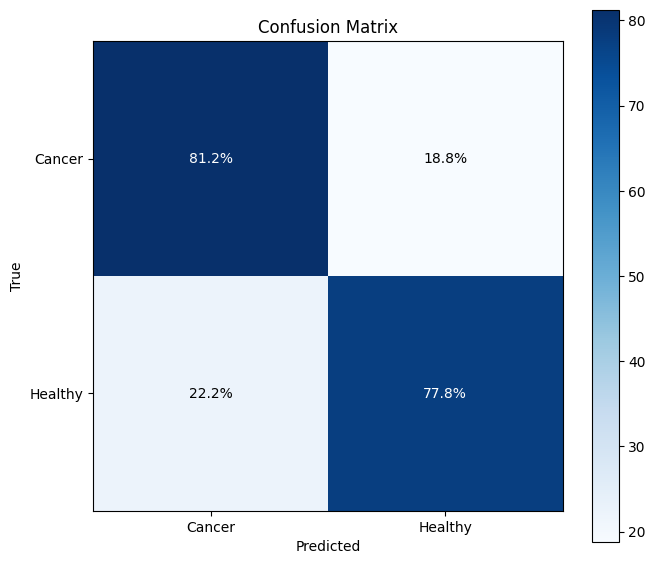

In [9]:
plot_confusion_matrix_custom(
    y_true, y_pred, class_names=["Cancer", "Healthy"], normalize=False
)
plot_confusion_matrix_custom(
    y_true, y_pred, class_names=["Cancer", "Healthy"], normalize=True
)

**RF**

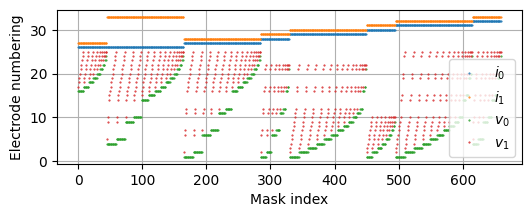

(186, 5280)


In [10]:
Msel = "Adj. far"
Fsel = "Top 8"
if parameter_type == "default":
    m = RandomForestClassifier()
elif parameter_type == "tuned":
    m = RandomForestClassifier(
        n_estimators=100,
        max_depth=510,
        max_features="log2",
        min_samples_split=2,
        min_samples_leaf=1,
    )

mask.IIVV_mask(Mask_sel[Msel], plot=True)
# select freq and IIVV and shape data
X_tmp = X[:, Freq_sel[Fsel], :]
X_tmp = X_tmp[:, :, mask.mask]
X_tmp = X_tmp.reshape(X_tmp.shape[0], -1)
print(X_tmp.shape)

In [11]:
y_true = []
y_score = []
y_pred = []

predict_durations = []
pred_test_samples = 0

# Cross-validation loop
for train_idx, test_idx in cv.split(X_tmp, Y_labels, Case):
    X_train, X_test = X_tmp[train_idx], X_tmp[test_idx]
    y_train, y_test = Y_labels[train_idx], Y_labels[test_idx]

    m.fit(X_train, y_train)

    t0 = time.time()
    probs = m.predict_proba(X_test)
    preds = np.argmax(probs, axis=1)
    t1 = time.time()

    pred_test_samples += len(test_idx)
    predict_durations.append((t1 - t0))

    y_true.extend(y_test)
    y_score.extend(probs)
    y_pred.extend(preds)

y_true = np.array(y_true)
y_score = np.array(y_score)
y_pred = np.array(y_pred)

acc = accuracy_score(y_true, y_pred)
print("CV Accuracy:", acc)

CV Accuracy: 0.8010752688172043


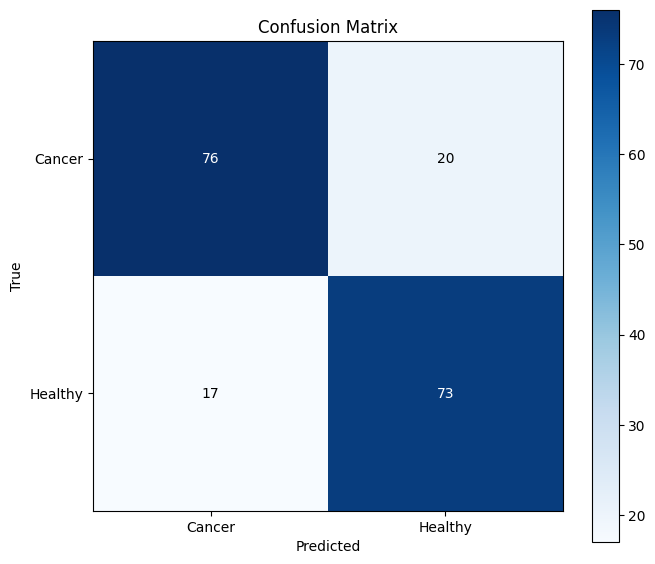

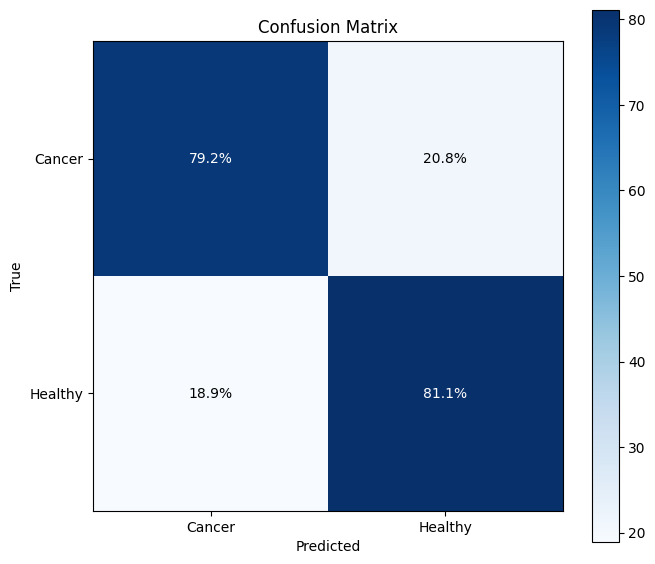

In [12]:
plot_confusion_matrix_custom(
    y_true, y_pred, class_names=["Cancer", "Healthy"], normalize=False
)
plot_confusion_matrix_custom(
    y_true, y_pred, class_names=["Cancer", "Healthy"], normalize=True
)

In [13]:
np.savez(
    f"{results_path}/timings_{parameter_type}_{class_task}_RF.npz",
    model_type="Tuned",
    model="RF",
    class_task=class_task,
    timings_CV_iter=predict_durations,
)

AUC = 0.8996527777777777


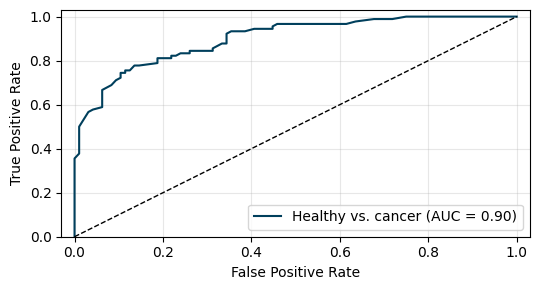

In [14]:
ResultsROCAUC(
    class_task,
    y_true,
    y_score,
    Y_labels,
    s_name=f"{results_path}/ROC_{parameter_type}_{class_task}_RF.pdf",
)

**LR**

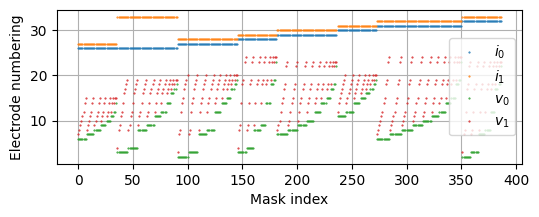

(186, 1935)


In [15]:
Msel = "Med. adj."
Fsel = "Top 5"
if parameter_type == "default":
    m = LogisticRegression()
elif parameter_type == "tuned":
    m = LogisticRegression(C=0.01, max_iter=100)

mask.IIVV_mask(Mask_sel[Msel], plot=True)

X_tmp = X[:, Freq_sel[Fsel], :]
X_tmp = X_tmp[:, :, mask.mask]
X_tmp = X_tmp.reshape(X_tmp.shape[0], -1)
print(X_tmp.shape)

In [16]:
y_true = []
y_score = []
y_pred = []

predict_durations = []
pred_test_samples = 0

# Cross-validation loop
for train_idx, test_idx in cv.split(X_tmp, Y_labels, Case):
    X_train, X_test = X_tmp[train_idx], X_tmp[test_idx]
    y_train, y_test = Y_labels[train_idx], Y_labels[test_idx]
    m.fit(X_train, y_train)

    t0 = time.time()
    probs = m.predict_proba(X_test)
    preds = np.argmax(probs, axis=1)
    t1 = time.time()

    pred_test_samples += len(test_idx)
    predict_durations.append((t1 - t0))

    y_true.extend(y_test)
    y_score.extend(probs)
    y_pred.extend(preds)

y_true = np.array(y_true)
y_score = np.array(y_score)
y_pred = np.array(y_pred)

acc = accuracy_score(y_true, y_pred)

In [17]:
np.savez(
    f"{results_path}/timings_{parameter_type}_{class_task}_LR.npz",
    model_type="Tuned",
    model="LR",
    class_task=class_task,
    timings_CV_iter=predict_durations,
)

AUC = 0.8760416666666666


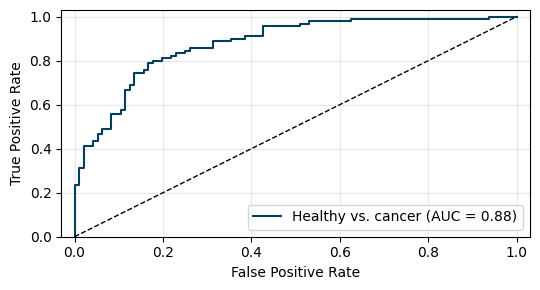

In [18]:
ResultsROCAUC(
    class_task,
    y_true,
    y_score,
    Y_labels,
    s_name=f"{results_path}/ROC_{parameter_type}_{class_task}_LR.pdf",
)

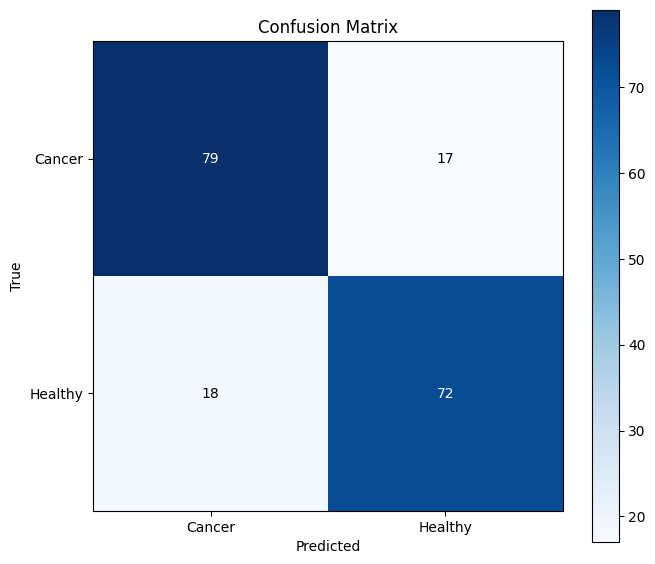

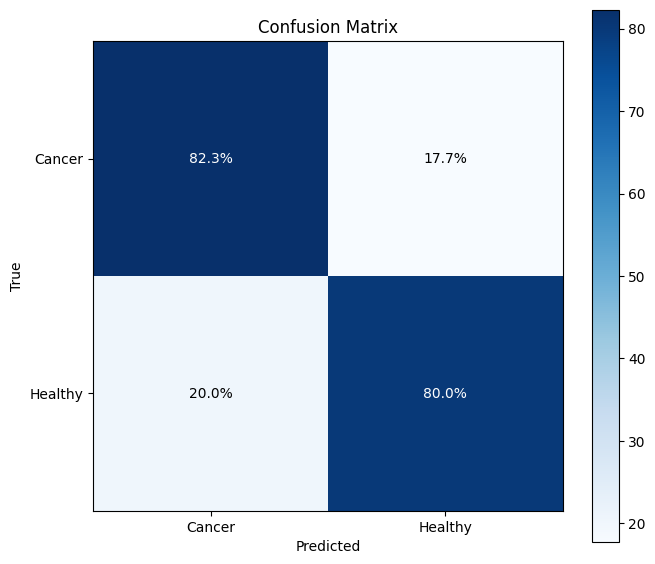

In [19]:
plot_confusion_matrix_custom(
    y_true, y_pred, class_names=["Cancer", "Healthy"], normalize=False
)
plot_confusion_matrix_custom(
    y_true, y_pred, class_names=["Cancer", "Healthy"], normalize=True
)

## Task 2 : Cancer vs. Low risk vs. High risk


	Info:	np.abs(Zdata)

Remaining data samples: 276 
	Info:	Select only data Avg_Cutpats <60%

Remaining data samples: 260 

	Info:	z-score Zdata
before: 443.1566344679978 707.062822308054
Normalized along the frequency axis.

after: -6.353090079251737e-18 0.9999999999999997

	Info:	np.nan_to_num(Zdata)

Remaining data samples: 260 

Healthy vs. LR vs. HR

Cancer: 96 entries
High risk: 29 entries
Low risk: 41 entries
Available cases: ['Cancer' 'High risk' 'Low risk']
Coding: -> forward
{'Cancer': [1, 0, 0], 'High risk': [0, 1, 0], 'Low risk': [0, 0, 1]}


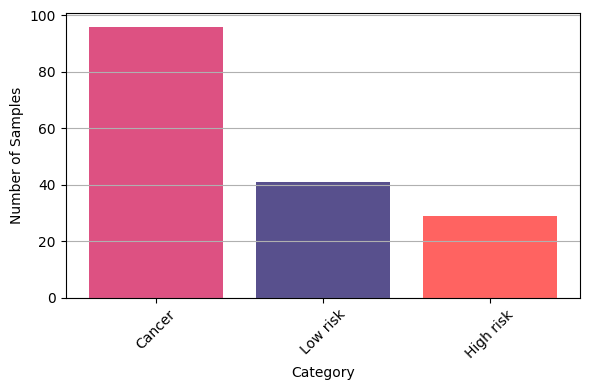


Inverse mapping: {(1, 0, 0): 'Cancer', (0, 1, 0): 'High risk', (0, 0, 1): 'Low risk'}
(166, 31, 7728) (166, 3) (166,)


In [20]:
class_task = "cancer_vs_lr_hr"

Freq_sel, Mask_sel = load_top_Fsel_Msel(class_task)
X, Y_labels, labels, Case, inverse_mapping, Y = Results_data_loading(class_task)

**SVM**

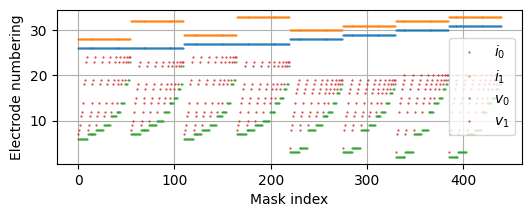

(166, 880)


In [21]:
Msel = "Skip1 medium"
Fsel = "Top 2"
if parameter_type == "default":
    m = SVC(probability=True, random_state=0)
elif parameter_type == "tuned":
    m = SVC(kernel="linear", C=0.1, probability=True, random_state=0)

mask.IIVV_mask(Mask_sel[Msel], plot=True)

X_tmp = X[:, Freq_sel[Fsel], :]
X_tmp = X_tmp[:, :, mask.mask]
X_tmp = X_tmp.reshape(X_tmp.shape[0], -1)
print(X_tmp.shape)

In [22]:
y_true = []
y_score = []
y_pred = []

predict_durations = []
pred_test_samples = 0

# Cross-validation loop
for train_idx, test_idx in cv.split(X_tmp, Y_labels, Case):
    X_train, X_test = X_tmp[train_idx], X_tmp[test_idx]
    y_train, y_test = Y_labels[train_idx], Y_labels[test_idx]

    m.fit(X_train, y_train)

    t0 = time.time()
    probs = m.predict_proba(X_test)
    preds = np.argmax(probs, axis=1)
    t1 = time.time()

    pred_test_samples += len(test_idx)
    predict_durations.append((t1 - t0))

    y_true.extend(y_test)
    y_score.extend(probs)
    y_pred.extend(preds)

y_true = np.array(y_true)
y_score = np.array(y_score)
y_pred = np.array(y_pred)

acc = accuracy_score(y_true, y_pred)
print("CV Accuracy:", acc)

CV Accuracy: 0.6144578313253012


In [23]:
np.savez(
    f"{results_path}/timings_{parameter_type}_{class_task}_SVM.npz",
    model_type="Tuned",
    model="SVM",
    class_task=class_task,
    timings_CV_iter=predict_durations,
)

Micro-average AUC = 0.8010596603280593


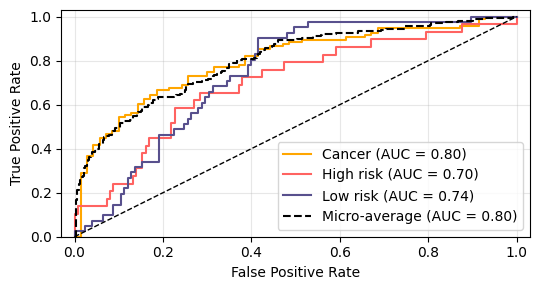

In [24]:
ResultsROCAUC(
    class_task,
    y_true,
    y_score,
    Y_labels,
    s_name=f"{results_path}/ROC_{parameter_type}_{class_task}_SVM.pdf",
)

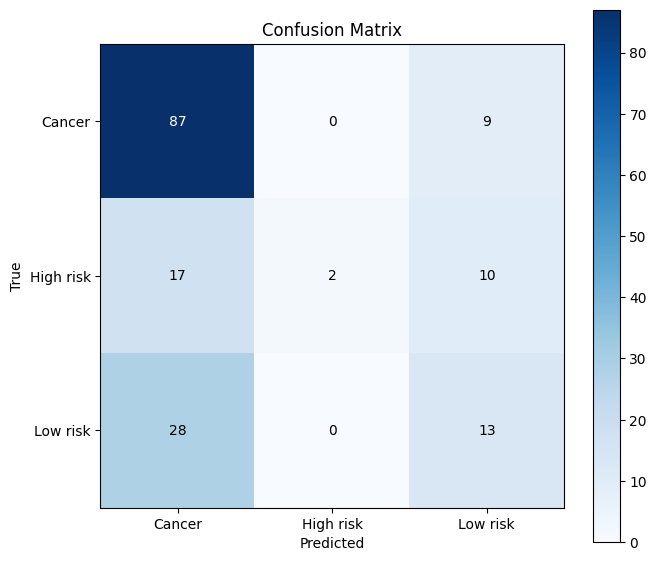

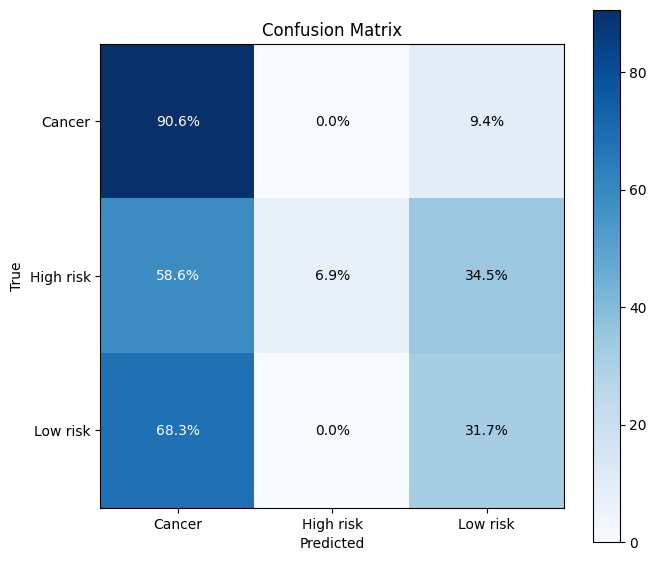

In [25]:
plot_confusion_matrix_custom(
    y_true, y_pred, class_names=["Cancer", "High risk", "Low risk"], normalize=False
)
plot_confusion_matrix_custom(
    y_true, y_pred, class_names=["Cancer", "High risk", "Low risk"], normalize=True
)

**RF**

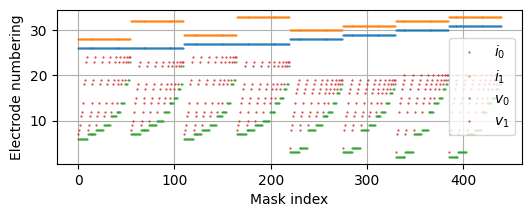

(166, 7480)


In [26]:
Msel = "Skip1 medium"
Fsel = "Top 17"
if parameter_type == "default":
    m = RandomForestClassifier()
elif parameter_type == "tuned":
    m = RandomForestClassifier(
        n_estimators=100,
        max_depth=510,
        max_features="log2",
        min_samples_split=2,
        min_samples_leaf=4,
    )

mask.IIVV_mask(Mask_sel[Msel], plot=True)
# select freq and IIVV and shape data
X_tmp = X[:, Freq_sel[Fsel], :]
X_tmp = X_tmp[:, :, mask.mask]
X_tmp = X_tmp.reshape(X_tmp.shape[0], -1)
print(X_tmp.shape)

In [27]:
y_true = []
y_score = []
y_pred = []

predict_durations = []
pred_test_samples = 0

# Cross-validation loop
for train_idx, test_idx in cv.split(X_tmp, Y_labels, Case):
    X_train, X_test = X_tmp[train_idx], X_tmp[test_idx]
    y_train, y_test = Y_labels[train_idx], Y_labels[test_idx]

    m.fit(X_train, y_train)

    t0 = time.time()
    probs = m.predict_proba(X_test)
    preds = np.argmax(probs, axis=1)
    t1 = time.time()

    pred_test_samples += len(test_idx)
    predict_durations.append((t1 - t0))

    y_true.extend(y_test)
    y_score.extend(probs)
    y_pred.extend(preds)

y_true = np.array(y_true)
y_score = np.array(y_score)
y_pred = np.array(y_pred)

acc = accuracy_score(y_true, y_pred)
print("CV Accuracy:", acc)

CV Accuracy: 0.6325301204819277


In [28]:
np.savez(
    f"{results_path}/timings_{parameter_type}_{class_task}_RF.npz",
    model_type="Tuned",
    model="RF",
    class_task=class_task,
    timings_CV_iter=predict_durations,
)

Micro-average AUC = 0.8052692698504862


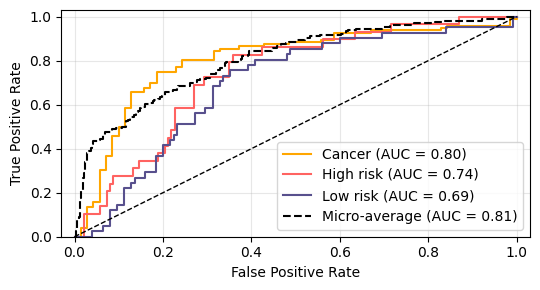

In [29]:
ResultsROCAUC(
    class_task,
    y_true,
    y_score,
    Y_labels,
    s_name=f"{results_path}/ROC_{parameter_type}_{class_task}_RF.pdf",
)

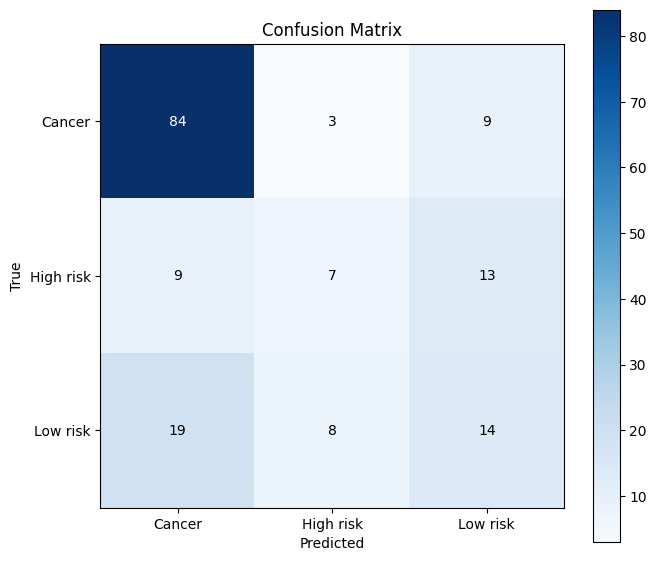

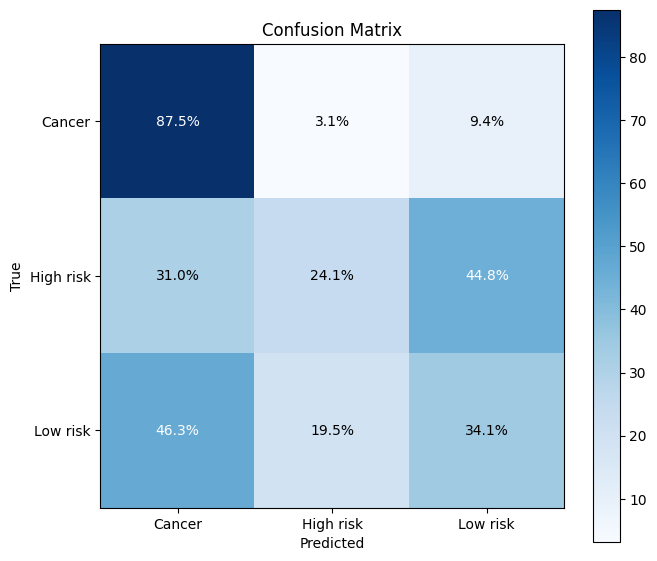

In [30]:
plot_confusion_matrix_custom(
    y_true, y_pred, class_names=["Cancer", "High risk", "Low risk"], normalize=False
)
plot_confusion_matrix_custom(
    y_true, y_pred, class_names=["Cancer", "High risk", "Low risk"], normalize=True
)

**LR**

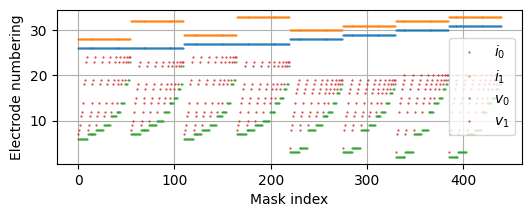

(166, 1760)


In [31]:
Msel = "Skip1 medium"
Fsel = "Top 4"
if parameter_type == "default":
    m = LogisticRegression()
elif parameter_type == "tuned":
    m = LogisticRegression(C=1.0, max_iter=100)

mask.IIVV_mask(Mask_sel[Msel], plot=True)

X_tmp = X[:, Freq_sel[Fsel], :]
X_tmp = X_tmp[:, :, mask.mask]
X_tmp = X_tmp.reshape(X_tmp.shape[0], -1)
print(X_tmp.shape)

In [32]:
y_true = []
y_score = []
y_pred = []

predict_durations = []
pred_test_samples = 0

# Cross-validation loop
for train_idx, test_idx in cv.split(X_tmp, Y_labels, Case):
    X_train, X_test = X_tmp[train_idx], X_tmp[test_idx]
    y_train, y_test = Y_labels[train_idx], Y_labels[test_idx]

    m.fit(X_train, y_train)

    t0 = time.time()
    probs = m.predict_proba(X_test)
    preds = np.argmax(probs, axis=1)
    t1 = time.time()

    pred_test_samples += len(test_idx)
    predict_durations.append((t1 - t0))

    y_true.extend(y_test)
    y_score.extend(probs)
    y_pred.extend(preds)

y_true = np.array(y_true)
y_score = np.array(y_score)
y_pred = np.array(y_pred)

acc = accuracy_score(y_true, y_pred)
print("CV Accuracy:", acc)

CV Accuracy: 0.6626506024096386


In [33]:
np.savez(
    f"{results_path}/timings_{parameter_type}_{class_task}_LR.npz",
    model_type="Tuned",
    model="LR",
    class_task=class_task,
    timings_CV_iter=predict_durations,
)

Micro-average AUC = 0.8106945855712004


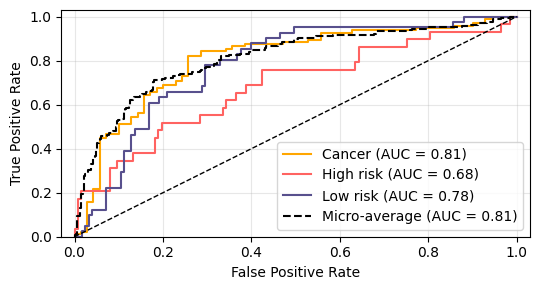

In [34]:
ResultsROCAUC(
    class_task,
    y_true,
    y_score,
    Y_labels,
    s_name=f"{results_path}/ROC_{parameter_type}_{class_task}_LR.pdf",
)

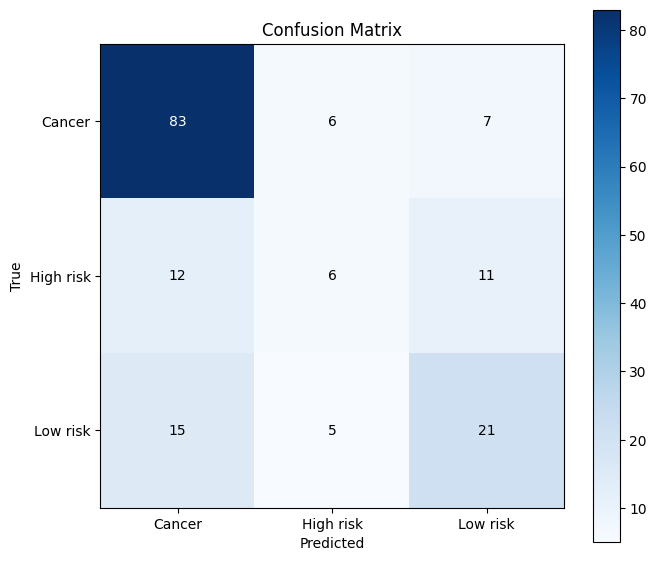

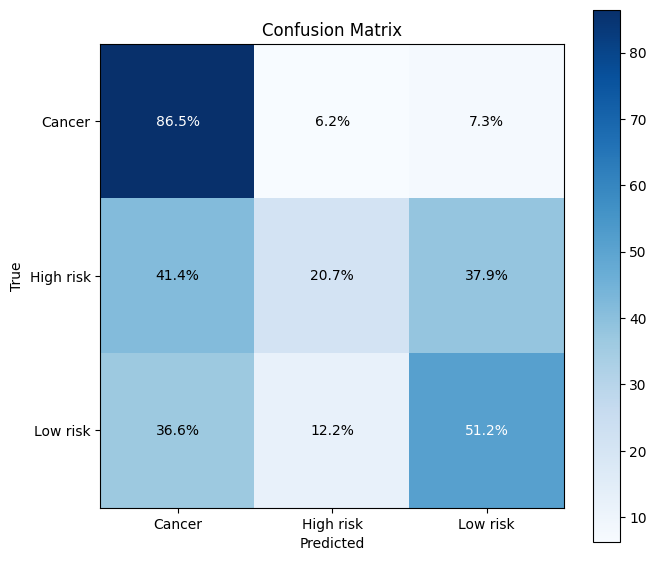

In [35]:
plot_confusion_matrix_custom(
    y_true, y_pred, class_names=["Cancer", "High risk", "Low risk"], normalize=False
)
plot_confusion_matrix_custom(
    y_true, y_pred, class_names=["Cancer", "High risk", "Low risk"], normalize=True
)

In [36]:
X_train.shape

(133, 1760)

## Task 3: Multiclass


	Info:	np.abs(Zdata)

Remaining data samples: 276 
	Info:	Select only data Avg_Cutpats <60%

Remaining data samples: 260 

	Info:	z-score Zdata
before: 443.1566344679978 707.062822308054
Normalized along the frequency axis.

after: -6.353090079251737e-18 0.9999999999999997

	Info:	np.nan_to_num(Zdata)

Remaining data samples: 260 

MC

Healthy: 90 entries
Cancer: 96 entries
High-grade dysplasia: 29 entries
Non-malignant: 41 entries
Available cases: ['Cancer' 'Healthy' 'High-grade dysplasia' 'Non-malignant']
Coding: -> forward
{'Cancer': [1, 0, 0, 0], 'Healthy': [0, 1, 0, 0], 'High-grade dysplasia': [0, 0, 1, 0], 'Non-malignant': [0, 0, 0, 1]}


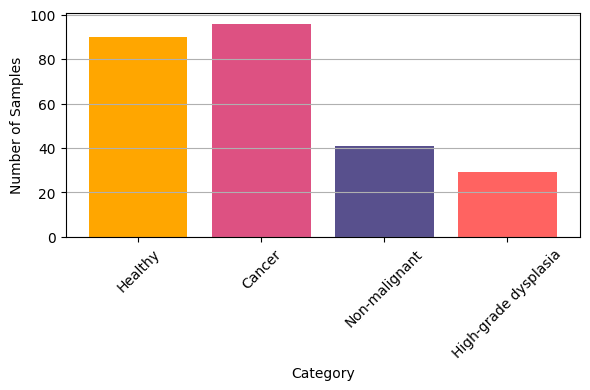


Inverse mapping: {(1, 0, 0, 0): 'Cancer', (0, 1, 0, 0): 'Healthy', (0, 0, 1, 0): 'High-grade dysplasia', (0, 0, 0, 1): 'Non-malignant'}
(256, 31, 7728) (256, 4) (256,)


In [37]:
class_task = "MC"

Freq_sel, Mask_sel = load_top_Fsel_Msel(class_task)
X, Y_labels, labels, Case, inverse_mapping, Y = Results_data_loading(
    class_task, data_augmentation=False  # augmentation done after train test split
)

**SVM**

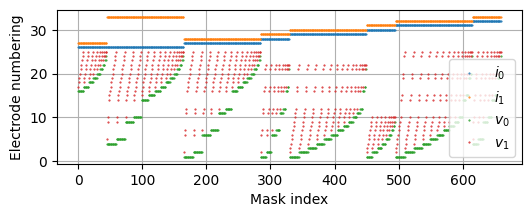

(256, 18480)


In [38]:
Msel = "Adj. far"
Fsel = "Top 28"
if parameter_type == "default":
    m = SVC(probability=True, random_state=0)
elif parameter_type == "tuned":
    m = SVC(kernel="rbf", C=1.0, probability=True, random_state=0)

mask.IIVV_mask(Mask_sel[Msel], plot=True)

X_tmp = X[:, Freq_sel[Fsel], :]
X_tmp = X_tmp[:, :, mask.mask]
X_tmp = X_tmp.reshape(X_tmp.shape[0], -1)
print(X_tmp.shape)

In [39]:
y_true = []
y_score = []
y_pred = []

predict_durations = []
pred_test_samples = 0

# Cross-validation loop
for train_idx, test_idx in cv.split(X_tmp, Y_labels, Case):
    X_train, X_test = X_tmp[train_idx], X_tmp[test_idx]
    y_train, y_test = Y_labels[train_idx], Y_labels[test_idx]

    m.fit(X_train, y_train)

    t0 = time.time()
    probs = m.predict_proba(X_test)
    preds = np.argmax(probs, axis=1)
    t1 = time.time()

    pred_test_samples += len(test_idx)
    predict_durations.append((t1 - t0))

    y_true.extend(y_test)
    y_score.extend(probs)
    y_pred.extend(preds)

y_true = np.array(y_true)
y_score = np.array(y_score)
y_pred = np.array(y_pred)

acc = accuracy_score(y_true, y_pred)
print("CV Accuracy:", acc)

CV Accuracy: 0.58984375


In [40]:
np.savez(
    f"{results_path}/timings_{parameter_type}_{class_task}_SVM.npz",
    model_type="Tuned",
    model="SVM",
    class_task=class_task,
    timings_CV_iter=predict_durations,
)

Micro-average AUC = 0.7864990234375


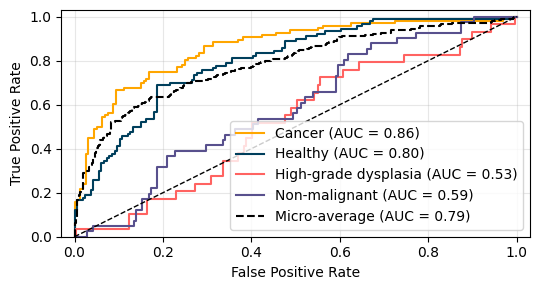

In [41]:
ResultsROCAUC(
    class_task,
    y_true,
    y_score,
    Y_labels,
    s_name=f"{results_path}/ROC_{parameter_type}_{class_task}_SVM.pdf",
)

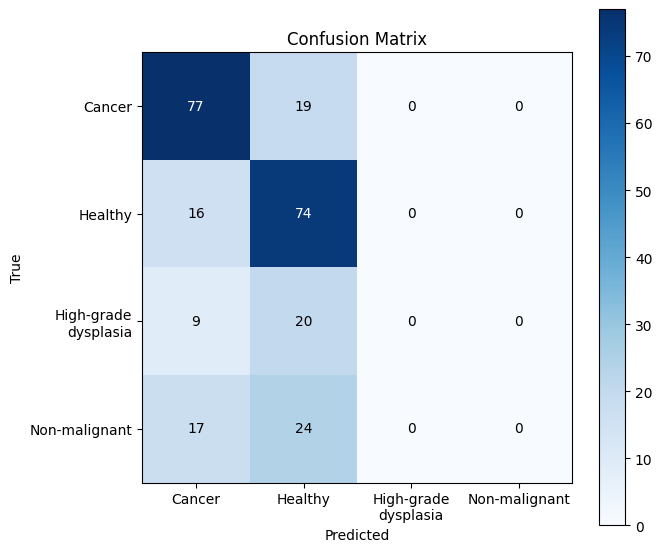

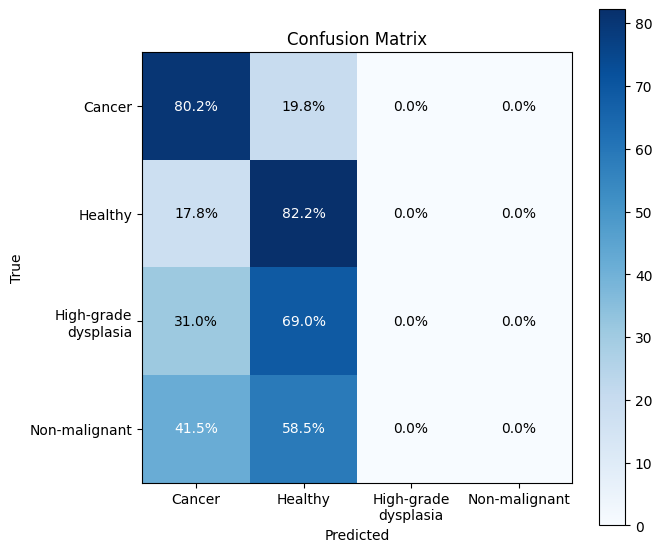

In [42]:
plot_confusion_matrix_custom(
    y_true,
    y_pred,
    class_names=["Cancer", "Healthy", "High-grade\ndysplasia", "Non-malignant"],
    normalize=False,
)
plot_confusion_matrix_custom(
    y_true,
    y_pred,
    class_names=["Cancer", "Healthy", "High-grade\ndysplasia", "Non-malignant"],
    normalize=True,
)

**RF**

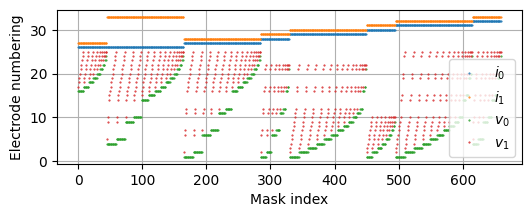

(256, 18480)


In [43]:
Msel = "Adj. far"
Fsel = "Top 28"
if parameter_type == "default":
    m = RandomForestClassifier()
elif parameter_type == "tuned":
    m = RandomForestClassifier(
        n_estimators=100,
        max_depth=510,
        max_features="sqrt",
        min_samples_split=2,
        min_samples_leaf=4,
    )

mask.IIVV_mask(Mask_sel[Msel], plot=True)

X_tmp = X[:, Freq_sel[Fsel], :]
X_tmp = X_tmp[:, :, mask.mask]
X_tmp = X_tmp.reshape(X_tmp.shape[0], -1)
print(X_tmp.shape)

In [44]:
y_true = []
y_score = []
y_pred = []

predict_durations = []
pred_test_samples = 0

# Cross-validation loop
for train_idx, test_idx in cv.split(X_tmp, Y_labels, Case):
    X_train, X_test = X_tmp[train_idx], X_tmp[test_idx]
    y_train, y_test = Y_labels[train_idx], Y_labels[test_idx]

    m.fit(X_train, y_train)

    t0 = time.time()
    probs = m.predict_proba(X_test)
    preds = np.argmax(probs, axis=1)
    t1 = time.time()

    pred_test_samples += len(test_idx)
    predict_durations.append((t1 - t0))

    y_true.extend(y_test)
    y_score.extend(probs)
    y_pred.extend(preds)

y_true = np.array(y_true)
y_score = np.array(y_score)
y_pred = np.array(y_pred)

acc = accuracy_score(y_true, y_pred)
print("CV Accuracy:", acc)

CV Accuracy: 0.5859375


In [45]:
np.savez(
    f"{results_path}/timings_{parameter_type}_{class_task}_RF.npz",
    model_type="Tuned",
    model="RF",
    class_task=class_task,
    timings_CV_iter=predict_durations,
)

Micro-average AUC = 0.8194020589192708


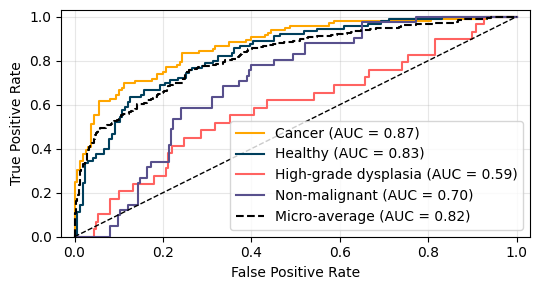

In [46]:
ResultsROCAUC(
    class_task,
    y_true,
    y_score,
    Y_labels,
    s_name=f"{results_path}/ROC_{parameter_type}_{class_task}_RF.pdf",
)

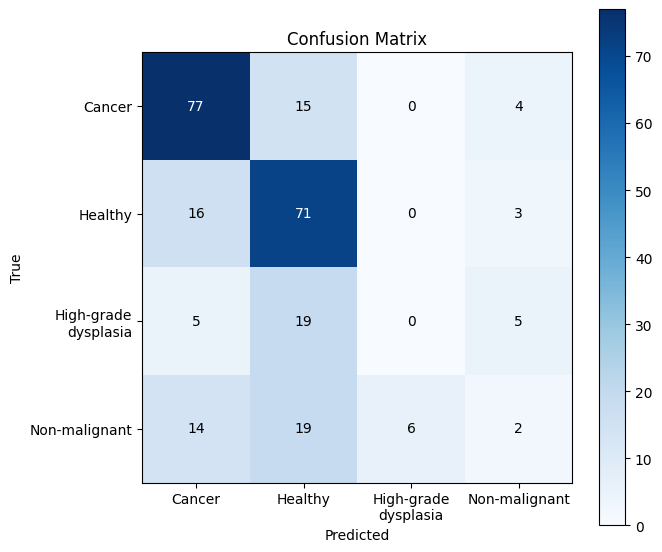

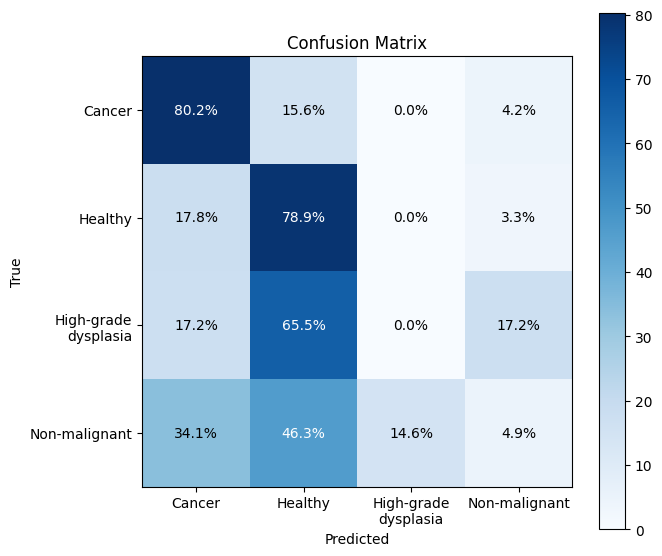

In [47]:
plot_confusion_matrix_custom(
    y_true,
    y_pred,
    class_names=["Cancer", "Healthy", "High-grade\ndysplasia", "Non-malignant"],
    normalize=False,
)
plot_confusion_matrix_custom(
    y_true,
    y_pred,
    class_names=["Cancer", "Healthy", "High-grade\ndysplasia", "Non-malignant"],
    normalize=True,
)

**LR**

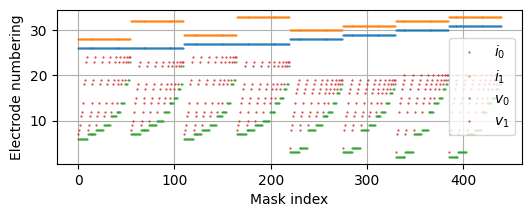

(256, 10120)


In [48]:
Msel = "Skip1 medium"
Fsel = "Top 23"
if parameter_type == "default":
    m = LogisticRegression()
elif parameter_type == "tuned":
    m = LogisticRegression(C=0.01, max_iter=100)

mask.IIVV_mask(Mask_sel[Msel], plot=True)

X_tmp = X[:, Freq_sel[Fsel], :]
X_tmp = X_tmp[:, :, mask.mask]
X_tmp = X_tmp.reshape(X_tmp.shape[0], -1)
print(X_tmp.shape)

In [49]:
y_true = []
y_score = []
y_pred = []

predict_durations = []
pred_test_samples = 0

# Cross-validation loop
for train_idx, test_idx in cv.split(X_tmp, Y_labels, Case):
    X_train, X_test = X_tmp[train_idx], X_tmp[test_idx]
    y_train, y_test = Y_labels[train_idx], Y_labels[test_idx]

    m.fit(X_train, y_train)

    t0 = time.time()
    probs = m.predict_proba(X_test)
    preds = np.argmax(probs, axis=1)
    t1 = time.time()

    pred_test_samples += len(test_idx)
    predict_durations.append((t1 - t0))

    y_true.extend(y_test)
    y_score.extend(probs)
    y_pred.extend(preds)

y_true = np.array(y_true)
y_score = np.array(y_score)
y_pred = np.array(y_pred)

acc = accuracy_score(y_true, y_pred)
print("CV Accuracy:", acc)

CV Accuracy: 0.59765625


In [50]:
np.savez(
    f"{results_path}/timings_{parameter_type}_{class_task}_LR.npz",
    model_type="Tuned",
    model="LR",
    class_task=class_task,
    timings_CV_iter=predict_durations,
)

Micro-average AUC = 0.7805887858072915


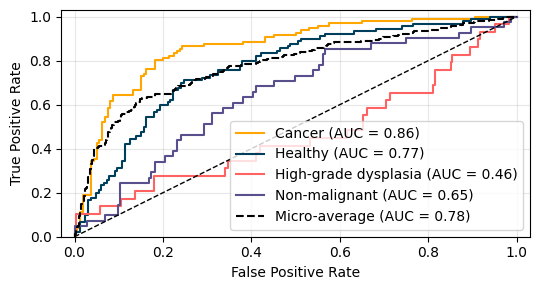

In [51]:
ResultsROCAUC(
    class_task,
    y_true,
    y_score,
    Y_labels,
    s_name=f"{results_path}/ROC_{parameter_type}_{class_task}_LR.pdf",
)

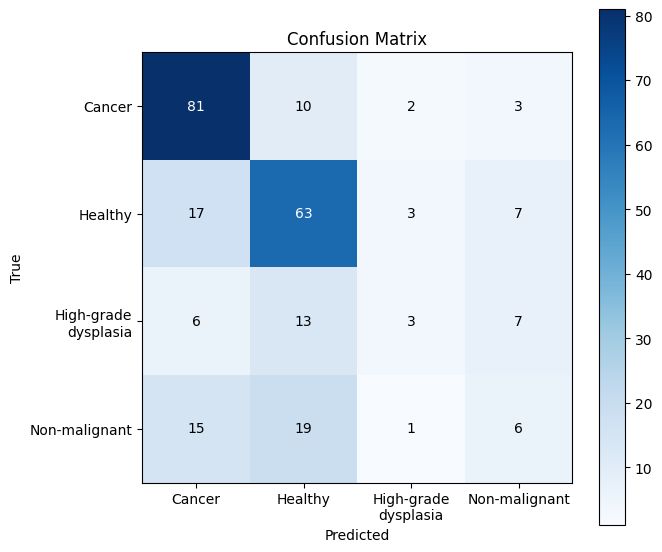

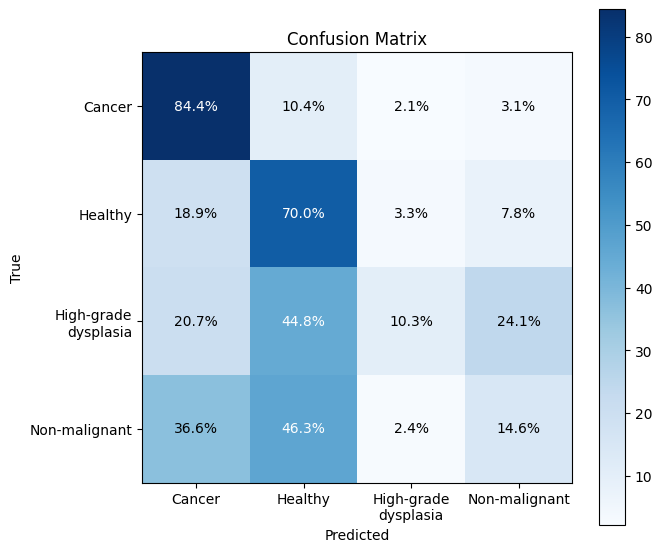

In [52]:
plot_confusion_matrix_custom(
    y_true,
    y_pred,
    class_names=["Cancer", "Healthy", "High-grade\ndysplasia", "Non-malignant"],
    normalize=False,
)
plot_confusion_matrix_custom(
    y_true,
    y_pred,
    class_names=["Cancer", "Healthy", "High-grade\ndysplasia", "Non-malignant"],
    normalize=True,
)

___